# Experiment 05 — Can a ReLU-Heavy MLP Represent a CNN's Learned Function?

The interactive companion to `experiments/05_function_distillation/`. Full
methodology and write-up: `experiments/05_function_distillation/README.md`.

**This is not an MNIST classification notebook.** The frozen CNN from
experiment 04 is a black box: `f_CNN(x) = logit`. Five flat-vector student
architectures — no convolution, no locality, no weight sharing, no pooling —
are trained to reproduce that function directly (`MSE(student_logit,
teacher_logit)`), never touching the original MNIST labels during training.
The question is whether a generic ReLU-heavy architecture can efficiently
*represent* a function a convolutional network discovered, and if so, what
about that architecture actually matters (depth? residual structure? raw
parameter count? parallel nonlinear features?).

This notebook loads and inspects results already produced by the pipeline
scripts (`generate_teacher_dataset.py → sweep.py → robustness_eval.py →
worst_case.py → make_plots.py`) rather than re-running the full 34-model
sweep interactively (~15 minutes on CPU) — see the README for exact
reproduction commands.

In [1]:
import csv
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.image as mpimg

REPO_ROOT = Path.cwd().parent
EXP_DIR = REPO_ROOT / "experiments" / "05_function_distillation"
OUTPUTS = EXP_DIR / "outputs"
sys.path.insert(0, str(EXP_DIR))

from make_plots import ARCH_STYLE, load_results  # noqa: E402

%matplotlib inline

results = load_results()
print(f"{len(results)} student configs loaded from {OUTPUTS / 'results.csv'}")

34 student configs loaded from E:\projects\PytorchExperiments\experiments\05_function_distillation\outputs\results.csv


## Headline comparison

Five representative models: the linear baseline, the best conventional MLP,
the largest plain (non-residual) MLP, its exactly parameter-matched
residual/compositional twin, and the largest parallel ReLU bank.

In [2]:
highlight_names = [
    "linear", "conventional_mlp_H128", "deepplain_H128_N8",
    "compositional_H128_N8", "parallel_B16_W32",
]
by_name = {r["name"]: r for r in results}

header = f'{"model":24s} {"params":>9s} {"ReLU layers":>12s} {"train MSE":>10s} {"val MSE":>9s} {"test MSE":>9s} {"agreement":>10s}'
print(header)
print("-" * len(header))
for name in highlight_names:
    r = by_name[name]
    print(f'{name:24s} {int(r["n_params"]):9d} {int(r["n_relu_layers"]):12d} '
          f'{r["train_mse"]:10.3f} {r["val_mse"]:9.3f} {r["test_mse"]:9.3f} '
          f'{r["test_teacher_student_agreement"]:10.4f}')

model                       params  ReLU layers  train MSE   val MSE  test MSE  agreement
-----------------------------------------------------------------------------------------
linear                         785            0     23.582    23.135    23.547     0.9240
conventional_mlp_H128       117121            2      0.988     1.387     1.383     0.9951
deepplain_H128_N8           496897           24      1.260     1.587     1.596     0.9939
compositional_H128_N8       496897           24      0.666     1.045     1.032     0.9957
parallel_B16_W32            402433           16      3.010     3.423     3.256     0.9815


## Test function error vs. capacity

Four views of the same 34 models: error against parameter count, against
the number of ReLU transformations, against approximate FLOPs, and teacher/
student classification agreement against parameter count. Colored by
architecture family.

C:\Users\Ashwin Prakash\AppData\Local\Temp\ipykernel_10852\3460534651.py:7: UserWarning: You passed a edgecolor/edgecolors ('black') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax.scatter(r[x_key], r[y_key], color=style["color"], marker=style["marker"],


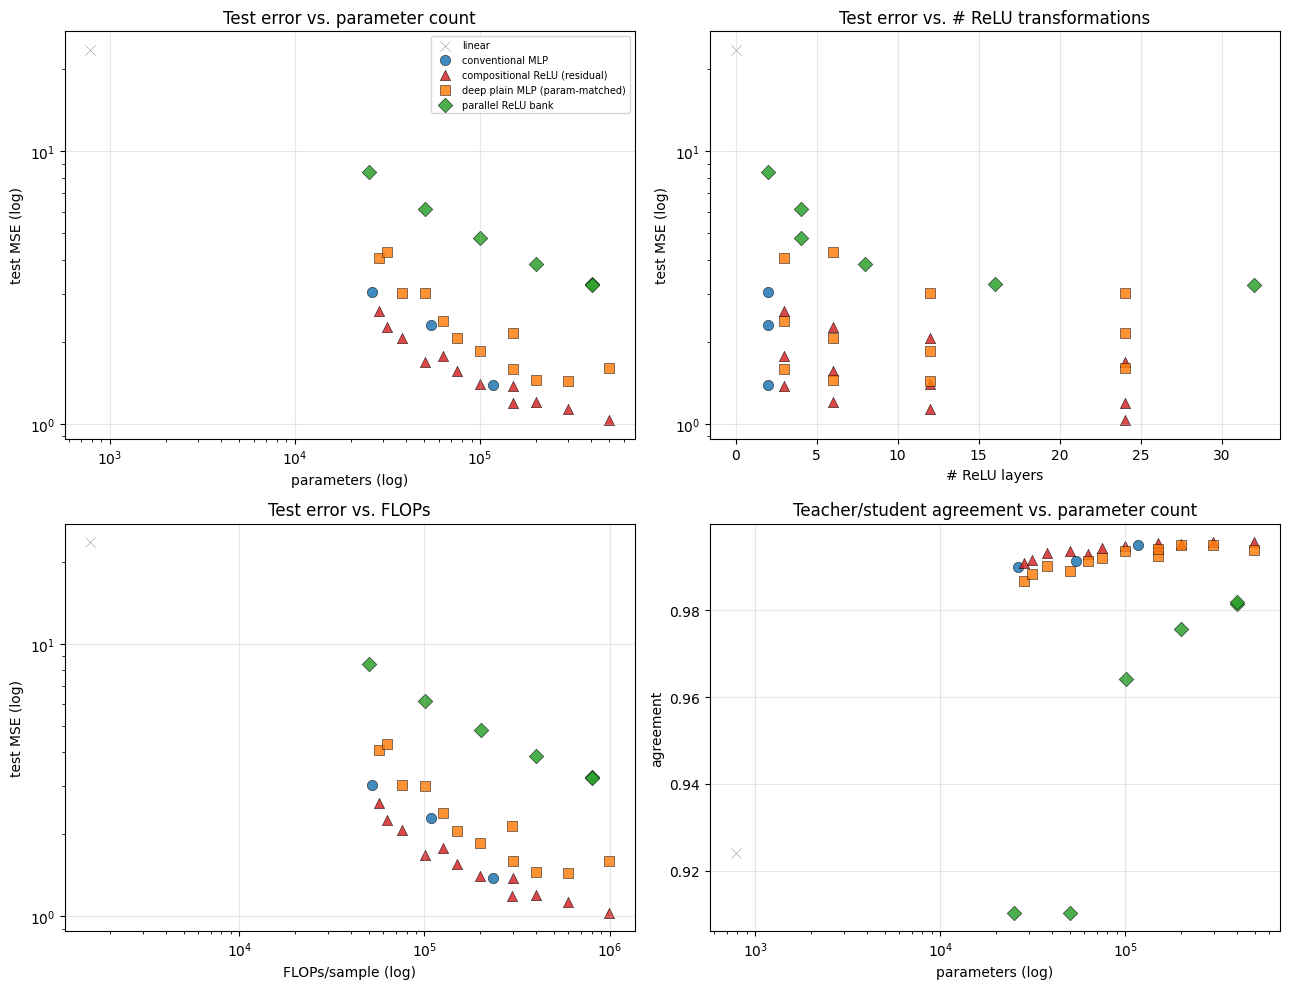

In [3]:
def scatter_by_arch(ax, x_key, y_key, logx=False, logy=False):
    seen = set()
    for r in results:
        style = ARCH_STYLE[r["arch"]]
        label = style["label"] if r["arch"] not in seen else None
        seen.add(r["arch"])
        ax.scatter(r[x_key], r[y_key], color=style["color"], marker=style["marker"],
                   s=55, alpha=0.85, label=label, edgecolors="black", linewidths=0.4)
    if logx: ax.set_xscale("log")
    if logy: ax.set_yscale("log")
    ax.grid(True, alpha=0.3)


fig, axes = plt.subplots(2, 2, figsize=(13, 10))

scatter_by_arch(axes[0, 0], "n_params", "test_mse", logx=True, logy=True)
axes[0, 0].set_xlabel("parameters (log)"); axes[0, 0].set_ylabel("test MSE (log)")
axes[0, 0].set_title("Test error vs. parameter count")
axes[0, 0].legend(fontsize=7)

scatter_by_arch(axes[0, 1], "n_relu_layers", "test_mse", logy=True)
axes[0, 1].set_xlabel("# ReLU layers"); axes[0, 1].set_ylabel("test MSE (log)")
axes[0, 1].set_title("Test error vs. # ReLU transformations")

scatter_by_arch(axes[1, 0], "flops_per_sample", "test_mse", logx=True, logy=True)
axes[1, 0].set_xlabel("FLOPs/sample (log)"); axes[1, 0].set_ylabel("test MSE (log)")
axes[1, 0].set_title("Test error vs. FLOPs")

scatter_by_arch(axes[1, 1], "n_params", "test_teacher_student_agreement", logx=True)
axes[1, 1].set_xlabel("parameters (log)"); axes[1, 1].set_ylabel("agreement")
axes[1, 1].set_title("Teacher/student agreement vs. parameter count")

fig.tight_layout()
plt.show()

## The core ablation: residual structure vs. depth, at IDENTICAL params

For every `(H, N)`, `compositional_relu` and `deep_plain_mlp` have exactly
the same parameter count (same width, same total linear-layer count) — the
only difference is the residual skip around each block. Any gap below is
attributable to that structural choice alone, not to extra capacity.

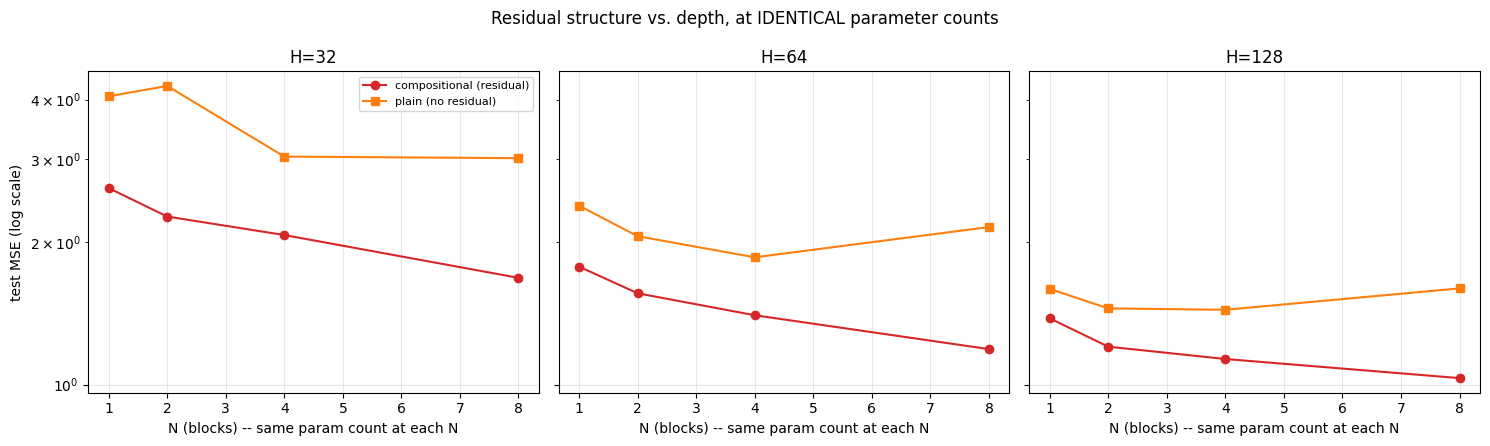

Plain deep_plain_mlp gets WORSE going from N=4 to N=8 at H=64 and H=128 --
the classic 'plain deep nets degrade with depth' pathology, reproduced at toy scale:
  H=64: plain N=4 -> 1.857   plain N=8 -> 2.151
  H=128: plain N=4 -> 1.438   plain N=8 -> 1.596


In [4]:
from collections import defaultdict

by_h = defaultdict(lambda: defaultdict(dict))
for r in results:
    if r["arch"] in ("compositional_relu", "deep_plain_mlp"):
        h = int(r["cfg_hidden"])
        n = int(r["cfg_n_blocks"]) if r["arch"] == "compositional_relu" else int(r["cfg_n_layers"]) // 3
        by_h[h][n][r["arch"]] = r["test_mse"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, h in zip(axes, sorted(by_h)):
    ns = sorted(by_h[h])
    comp = [by_h[h][n].get("compositional_relu") for n in ns]
    plain = [by_h[h][n].get("deep_plain_mlp") for n in ns]
    ax.plot(ns, comp, "o-", color=ARCH_STYLE["compositional_relu"]["color"], label="compositional (residual)")
    ax.plot(ns, plain, "s-", color=ARCH_STYLE["deep_plain_mlp"]["color"], label="plain (no residual)")
    ax.set_title(f"H={h}")
    ax.set_xlabel("N (blocks) -- same param count at each N")
    ax.set_yscale("log")
    ax.grid(True, alpha=0.3)
axes[0].set_ylabel("test MSE (log scale)")
axes[0].legend(fontsize=8)
fig.suptitle("Residual structure vs. depth, at IDENTICAL parameter counts")
fig.tight_layout()
plt.show()

print("Plain deep_plain_mlp gets WORSE going from N=4 to N=8 at H=64 and H=128 --")
print("the classic 'plain deep nets degrade with depth' pathology, reproduced at toy scale:")
for h in (64, 128):
    print(f"  H={h}: plain N=4 -> {by_h[h][4]['deep_plain_mlp']:.3f}   plain N=8 -> {by_h[h][8]['deep_plain_mlp']:.3f}")

## Robustness: does the student track the teacher's actual function, or
just the training image distribution?

Test images perturbed with small translation, rotation, Gaussian noise, and
brightness shifts (never seen during distillation); `CNN(x')` vs
`student(x')` compared on the *same* modified image.

In [5]:
with open(OUTPUTS / "robustness_results.csv") as f:
    rob_rows = list(csv.DictReader(f))

conditions = ["clean_test", "translate_2px", "rotate_10deg", "gaussian_noise", "brightness_1.3x"]
models_order = ["linear", "conventional_mlp_H128", "deepplain_H128_N8", "compositional_H128_N8", "parallel_B32_W16"]

header = f'{"model":24s}' + "".join(f'{c:>18s}' for c in conditions)
print(header)
for m in models_order:
    row = {r["condition"]: float(r["mse"]) for r in rob_rows if r["model"] == m}
    print(f'{m:24s}' + "".join(f'{row.get(c, float("nan")):18.2f}' for c in conditions))

model                           clean_test     translate_2px      rotate_10deg    gaussian_noise   brightness_1.3x
linear                               22.85             54.68             24.22             78.40             25.87
conventional_mlp_H128                 1.44              6.03              1.89              4.42              1.66
deepplain_H128_N8                     1.54              8.14              1.90             11.25              1.89
compositional_H128_N8                 0.99              5.88              1.42              6.48              1.16
parallel_B32_W16                      3.04              7.03              3.03              4.92              3.34


## Worst-case disagreements

The 16 test images where `compositional_H128_N8` disagrees most sharply
with the teacher CNN (by `|CNN_logit - MLP_logit|`). Red titles mark actual
*classification* disagreements (not just magnitude) -- generated by
`worst_case.py`, which also found these concentrate on the CNN's most
confident "not-8" predictions (large negative logits, the sparse tail of
the target distribution) rather than on any single weak part of the
student's internal representation (a dead-ReLU probe found no meaningful
difference between worst-case and typical-error batches).

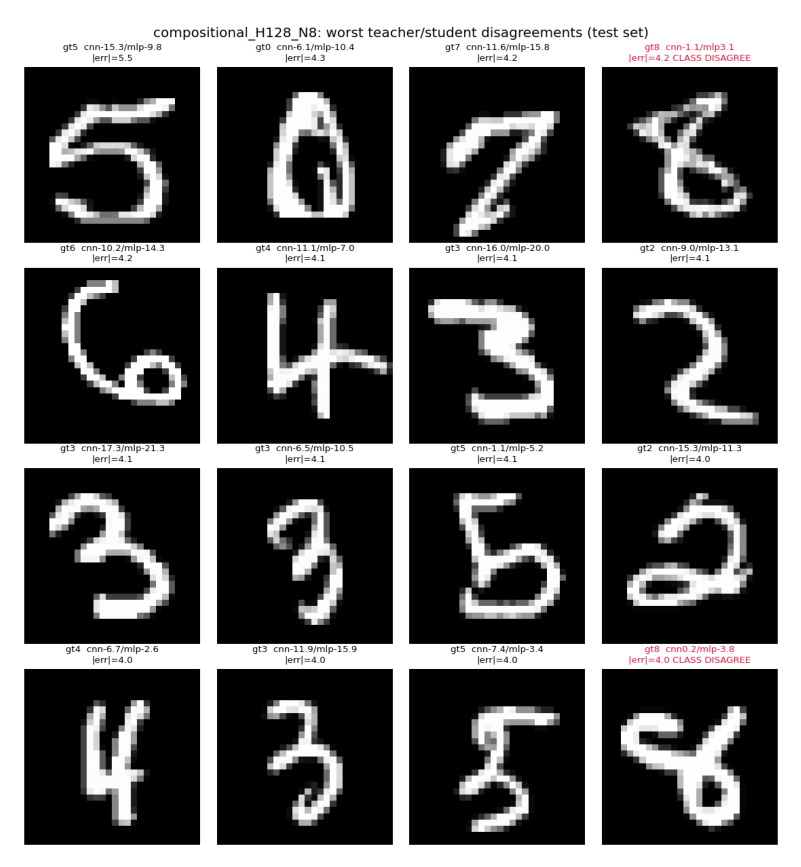

In [6]:
img = mpimg.imread(OUTPUTS / "worst_cases" / "compositional_H128_N8_worst_cases.png")
plt.figure(figsize=(11, 11))
plt.imshow(img)
plt.axis("off")
plt.show()

## Takeaways

- A generic ReLU-heavy MLP **can** closely approximate the CNN's learned
  function (best model: test MSE ≈ 1.03 on a ±32-range target, 99.57%
  classification agreement) -- with no convolutional inductive bias at all.
- **Structure matters, not just transformation count.** At identical
  parameter counts, residual composition beats plain depth, and plain depth
  sometimes *loses ground* as it gets deeper (N=4→8 at H=64, H=128) -- a
  toy-scale echo of the reason ResNets exist.
- The parallel ReLU feature bank -- nonlinear width without composition --
  was the weakest architecture at every parameter budget tested.
- Robustness to input perturbations is genuinely mixed: compositional wins
  on translation/rotation/brightness but **not** on Gaussian noise, where
  simpler models (even the weak parallel bank) score better.
- **Verdict:** partial, qualified support for the hypothesis. The weak form
  (a non-convolutional architecture can represent the function) holds; the
  strong form (ReLU transformation count alone is what matters, independent
  of structure) does not -- architecture still matters a great deal.

Full write-up, all 34 raw results, and reproduction commands:
`experiments/05_function_distillation/README.md`.